In [1]:
from pathlib import Path
import sys
import pandas as pd

# پیدا کردن ریشهٔ پروژه، چه از notebooks اجرا کنیم چه از ریشه
ROOT = Path.cwd()

if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from nhanes_analyzer import NhanesAnalyzer

# پسوند فایل‌های ارسالی تو کوچک است: .xpt
analyzer = NhanesAnalyzer(
    ROOT / "data" / "DEMO_L.xpt",
    ROOT / "data" / "BMX_L.xpt"
)

# هر شناسه باید نمایندهٔ فقط یک فرد باشد
assert analyzer.demo_df["SEQN"].is_unique
assert analyzer.bmx_df["SEQN"].is_unique

analyzer.merge_files()
analyzer.define_population(min_age=20)

adults = analyzer.analytical_population.copy()

# گمشدگی وزن را قبل از تعریف رویداد دودویی بررسی می‌کنیم
print("تعداد بزرگسالان پس از اتصال:", len(adults))
print("تعداد وزن‌های بدن گمشده:", adults["BMXWT"].isna().sum())

df = adults.dropna(
    subset=["BMXWT", "RIDAGEYR", "RIAGENDR", "WTMEC2YR"]
).copy()

df = df.loc[
    df["RIAGENDR"].isin([1, 2])
    & df["WTMEC2YR"].gt(0)
].copy()

print("تعداد افراد نمونهٔ نهایی:", len(df))

df[
    ["SEQN", "RIDAGEYR", "RIAGENDR", "BMXWT", "WTMEC2YR"]
].head()

تعداد بزرگسالان پس از اتصال: 6064
تعداد وزن‌های بدن گمشده: 81
تعداد افراد نمونهٔ نهایی: 5983


,SEQN,RIDAGEYR,RIAGENDR,BMXWT,WTMEC2YR
0,130378.0,43.0,1.0,86.9,54374.463898
1,130379.0,66.0,1.0,101.8,34084.721548
2,130380.0,44.0,2.0,69.4,81196.277992
5,130386.0,34.0,1.0,90.6,39988.452940
6,130387.0,68.0,2.0,103.5,20776.254850


In [2]:
# متغیرهای کمی
df["X_weight"] = df["BMXWT"]
df["Y_age"] = df["RIDAGEYR"]

# رویداد A: وزن بدن حداقل ۹۰ کیلوگرم
df["A"] = df["X_weight"] >= 90

# رویداد B: جنس ثبت‌شده مرد
df["B"] = df["RIAGENDR"] == 1

# متغیر تصادفی شاخص رویداد A:
# وقوع رویداد = ۱، عدم وقوع = ۰
df["I_A"] = df["A"].astype(int)

print("تعداد کل افراد:", len(df))
print("تعداد افراد با وزن حداقل ۹۰ کیلوگرم:", df["A"].sum())
print("تعداد مردان:", df["B"].sum())

df[
    ["X_weight", "Y_age", "RIAGENDR", "A", "B", "I_A"]
].head()

تعداد کل افراد: 5983
تعداد افراد با وزن حداقل ۹۰ کیلوگرم: 1939
تعداد مردان: 2688


,X_weight,Y_age,RIAGENDR,A,B,I_A
0,86.9,43.0,1.0,False,True,0
1,101.8,66.0,1.0,True,True,1
2,69.4,44.0,2.0,False,False,0
5,90.6,34.0,1.0,True,True,1
6,103.5,68.0,2.0,True,False,1


In [3]:
# تعداد کل افراد نمونهٔ نهایی
N = len(df)

# تعداد وقوع رویدادها
n_A = df["A"].sum()
n_B = df["B"].sum()

# علامت & یعنی هر دو شرط هم‌زمان برقرار باشند
n_AB = (df["A"] & df["B"]).sum()

# احتمال‌های تجربی بدون وزن‌دهی
p_A = n_A / N
p_B = n_B / N
p_AB = n_AB / N

probability_table = pd.DataFrame({
    "Event": ["A", "B", "A ∩ B"],
    "Count": [n_A, n_B, n_AB],
    "Probability": [p_A, p_B, p_AB],
    "Percent": [100 * p_A, 100 * p_B, 100 * p_AB]
})

probability_table.round(4)

,Event,Count,Probability,Percent
0,A,1939,0.3241,32.4085
1,B,2688,0.4493,44.9273
2,A ∩ B,1118,0.1869,18.6863


In [4]:
# ~ یعنی نقیض رویداد
# چون جنس را قبلاً به کدهای ۱ و ۲ محدود کردیم،
# ~B در نمونهٔ ما همان گروه زنان است.
n_not_B = (~df["B"]).sum()
n_A_not_B = (df["A"] & ~df["B"]).sum()

# احتمال وزن حداقل ۹۰، به شرط مرد یا زن بودن
p_A_given_B = n_AB / n_B
p_A_given_not_B = n_A_not_B / n_not_B

conditional_table = pd.DataFrame({
    "Group": ["Male", "Female"],
    "Group_size": [n_B, n_not_B],
    "Count_A": [n_AB, n_A_not_B],
    "P(A|Group)": [p_A_given_B, p_A_given_not_B],
    "Percent": [
        100 * p_A_given_B,
        100 * p_A_given_not_B
    ]
})

display(conditional_table.round(4))

# اختلاف دو احتمال بر حسب واحد درصد
difference_pp = 100 * (p_A_given_B - p_A_given_not_B)

print(f"Difference: {difference_pp:.2f} percentage points")

,Group,Group_size,Count_A,P(A|Group),Percent
0,Male,2688,1118,0.4159,41.5923
1,Female,3295,821,0.2492,24.9165


Difference: 16.68 percentage points


In [5]:
# احتمال مشترک در صورت استقلال
p_AB_if_independent = p_A * p_B

# تفاوت احتمال مشترک مشاهده‌شده با حاصل‌ضرب احتمال‌ها
independence_gap = p_AB - p_AB_if_independent

independence_table = pd.DataFrame({
    "Quantity": [
        "P(A and B)",
        "P(A) * P(B)",
        "P(A | B)",
        "P(A)"
    ],
    "Value": [
        p_AB,
        p_AB_if_independent,
        p_A_given_B,
        p_A
    ]
})

display(independence_table.round(4))

print(f"Joint probability gap: {independence_gap:.4f}")

,Quantity,Value
0,P(A and B),0.1869
1,P(A) * P(B),0.1456
2,P(A | B),0.4159
3,P(A),0.3241


Joint probability gap: 0.0413


In [6]:
# روش اول: قضیهٔ بیز
p_B_given_A_bayes = (p_A_given_B * p_B) / p_A

# روش دوم: محاسبهٔ مستقیم از تعدادها
p_B_given_A_direct = n_AB / n_A

bayes_table = pd.DataFrame({
    "Method": ["Bayes formula", "Direct count"],
    "P(B|A)": [
        p_B_given_A_bayes,
        p_B_given_A_direct
    ]
})

display(bayes_table.round(4))

# بررسی برابری دو روش با تحمل خطای محاسبات اعشاری
assert abs(p_B_given_A_bayes - p_B_given_A_direct) < 1e-12

print(f"P(B): {100 * p_B:.2f}%")
print(f"P(B|A): {100 * p_B_given_A_bayes:.2f}%")

,Method,P(B|A)
0,Bayes formula,0.5766
1,Direct count,0.5766


P(B): 44.93%
P(B|A): 57.66%


In [7]:
# پارامتر برنولی: احتمال وقوع رویداد A
p = p_A

# محاسبه با فرمول‌های برنولی
bernoulli_mean = p
bernoulli_variance = p * (1 - p)

# محاسبه مستقیم از توزیع تجربی صفر و یک‌ها
empirical_mean = df["I_A"].mean()
empirical_variance = df["I_A"].var(ddof=0)

bernoulli_table = pd.DataFrame({
    "Quantity": ["Mean", "Variance"],
    "Bernoulli_formula": [
        bernoulli_mean,
        bernoulli_variance
    ],
    "Empirical_calculation": [
        empirical_mean,
        empirical_variance
    ]
})

display(bernoulli_table.round(6))

,Quantity,Bernoulli_formula,Empirical_calculation
0,Mean,0.324085,0.324085
1,Variance,0.219054,0.219054


In [8]:
# تعداد افراد هر گروه
group_size = 30

# احتمال موفقیت؛ موفقیت اینجا فقط یعنی رخ‌دادن رویداد A
p = p_A

# امید و واریانس مدل دوجمله‌ای
binomial_mean = group_size * p
binomial_variance = group_size * p * (1 - p)
binomial_std = binomial_variance ** 0.5

binomial_table = pd.DataFrame({
    "Quantity": ["Mean", "Variance", "Standard deviation"],
    "Value": [
        binomial_mean,
        binomial_variance,
        binomial_std
    ]
})

display(binomial_table.round(4))

,Quantity,Value
0,Mean,9.7225
1,Variance,6.5716
2,Standard deviation,2.5635


In [9]:
import numpy as np

# ثابت‌بودن بذر باعث می‌شود اجرای دوباره، همان نتیجه را بدهد
rng = np.random.default_rng(1405)

repeats = 10_000
group_size = 30

# آرایهٔ صفر و یک: وضعیت رویداد A برای افراد نمونه
event_values = df["I_A"].to_numpy()

# محل ذخیرهٔ تعداد وقوع رویداد در هر زیرنمونه
counts = np.empty(repeats, dtype=int)

for i in range(repeats):
    subsample = rng.choice(
        event_values,
        size=group_size,
        replace=False
    )

    counts[i] = subsample.sum()

print("First 10 counts:", counts[:10])
print("Number of repetitions:", len(counts))

# واریانس دقیق شمارش در انتخاب بدون جایگذاری
N = len(event_values)
finite_population_correction = (N - group_size) / (N - 1)

hypergeometric_variance = (
    binomial_variance * finite_population_correction
)

comparison_table = pd.DataFrame({
    "Quantity": ["Mean", "Variance"],
    "Repeated_subsamples": [
        counts.mean(),
        counts.var(ddof=0)
    ],
    "Binomial_model": [
        binomial_mean,
        binomial_variance
    ],
    "Hypergeometric_model": [
        binomial_mean,
        hypergeometric_variance
    ]
})

display(comparison_table.round(4))

First 10 counts: [12  8 11 17 15  9  7 14 10 13]
Number of repetitions: 10000


,Quantity,Repeated_subsamples,Binomial_model,Hypergeometric_model
0,Mean,9.7560,9.7225,9.7225
1,Variance,6.4711,6.5716,6.5398


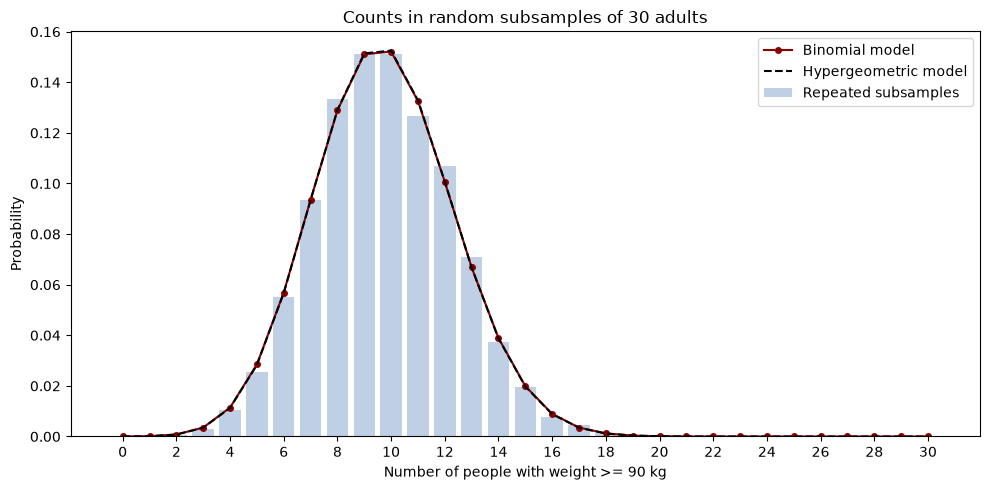

In [10]:
import matplotlib.pyplot as plt
from scipy.stats import binom, hypergeom

# تعدادهای ممکن: از صفر تا ۳۰ نفر
k = np.arange(group_size + 1)

# احتمال تجربی هر شمارش در ۱۰٬۰۰۰ تکرار
empirical_probs = (
    np.bincount(counts, minlength=group_size + 1) / repeats
)

# احتمال‌های مدل دوجمله‌ای
binomial_probs = binom.pmf(k, n=group_size, p=p)

# احتمال‌های مدل دقیق فوق‌هندسی
N = len(event_values)
M = int(event_values.sum())

hypergeometric_probs = hypergeom.pmf(
    k,
    M=N,             # اندازهٔ کل مجموعه
    n=M,             # تعداد افراد دارای رویداد A
    N=group_size     # اندازهٔ زیرنمونه
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    k, empirical_probs,
    color="lightsteelblue",
    label="Repeated subsamples",
    alpha=0.8
)

ax.plot(
    k, binomial_probs,
    "o-", color="darkred",
    markersize=4,
    label="Binomial model"
)

ax.plot(
    k, hypergeometric_probs,
    "--", color="black",
    label="Hypergeometric model"
)

ax.set_xlabel("Number of people with weight >= 90 kg")
ax.set_ylabel("Probability")
ax.set_title("Counts in random subsamples of 30 adults")
ax.set_xticks(np.arange(0, group_size + 1, 2))
ax.legend()

fig.tight_layout()

# ذخیرهٔ شکل برای گزارش
figure_dir = ROOT / "figures" / "phase2"
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "binomial_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

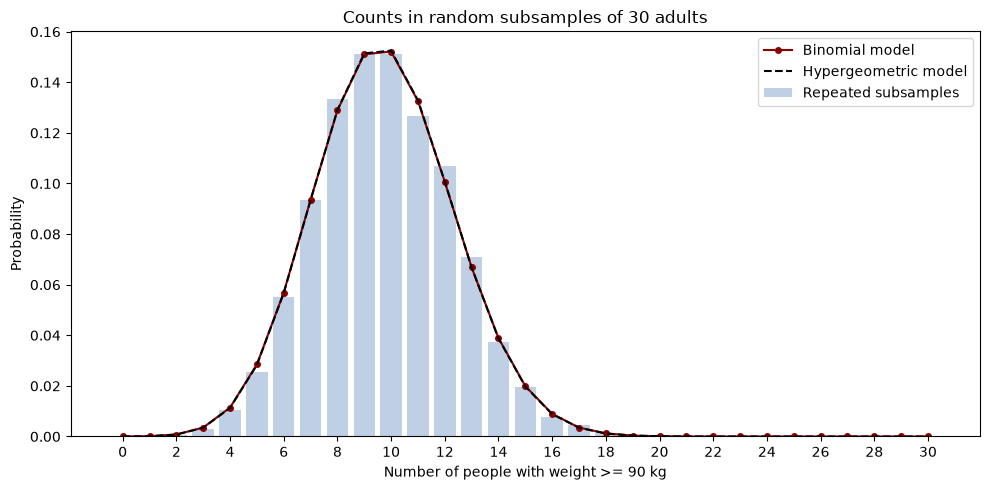

In [11]:
import matplotlib.pyplot as plt
from scipy.stats import binom, hypergeom

# تعدادهای ممکن: از صفر تا ۳۰ نفر
k = np.arange(group_size + 1)

# احتمال تجربی هر شمارش در ۱۰٬۰۰۰ تکرار
empirical_probs = (
    np.bincount(counts, minlength=group_size + 1) / repeats
)

# احتمال‌های مدل دوجمله‌ای
binomial_probs = binom.pmf(k, n=group_size, p=p)

# احتمال‌های مدل دقیق فوق‌هندسی
N = len(event_values)
M = int(event_values.sum())

hypergeometric_probs = hypergeom.pmf(
    k,
    M=N,             # اندازهٔ کل مجموعه
    n=M,             # تعداد افراد دارای رویداد A
    N=group_size     # اندازهٔ زیرنمونه
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    k, empirical_probs,
    color="lightsteelblue",
    label="Repeated subsamples",
    alpha=0.8
)

ax.plot(
    k, binomial_probs,
    "o-", color="darkred",
    markersize=4,
    label="Binomial model"
)

ax.plot(
    k, hypergeometric_probs,
    "--", color="black",
    label="Hypergeometric model"
)

ax.set_xlabel("Number of people with weight >= 90 kg")
ax.set_ylabel("Probability")
ax.set_title("Counts in random subsamples of 30 adults")
ax.set_xticks(np.arange(0, group_size + 1, 2))
ax.legend()

fig.tight_layout()

# ذخیرهٔ شکل برای گزارش
figure_dir = ROOT / "figures" / "phase2"
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "binomial_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [12]:
# وزن بدن؛ بر حسب کیلوگرم
weights = df["X_weight"]

mean_weight = weights.mean()

# واریانس و انحراف معیار توزیع تجربی: مخرج N
variance_weight = weights.var(ddof=0)
std_weight = weights.std(ddof=0)

# چولگی نمونه
skewness_weight = weights.skew()

weight_summary = pd.DataFrame({
    "Statistic": [
        "Mean (kg)",
        "Median (kg)",
        "Empirical variance (kg^2)",
        "Empirical standard deviation (kg)",
        "Skewness",
        "Minimum (kg)",
        "Maximum (kg)"
    ],
    "Value": [
        mean_weight,
        weights.median(),
        variance_weight,
        std_weight,
        skewness_weight,
        weights.min(),
        weights.max()
    ]
})

display(weight_summary.round(4))

,Statistic,Value
0,Mean (kg),83.2920
1,Median (kg),79.9000
2,Empirical variance (kg^2),500.5260
3,Empirical standard deviation (kg),22.3724
4,Skewness,1.1089
5,Minimum (kg),27.9000
6,Maximum (kg),248.2000


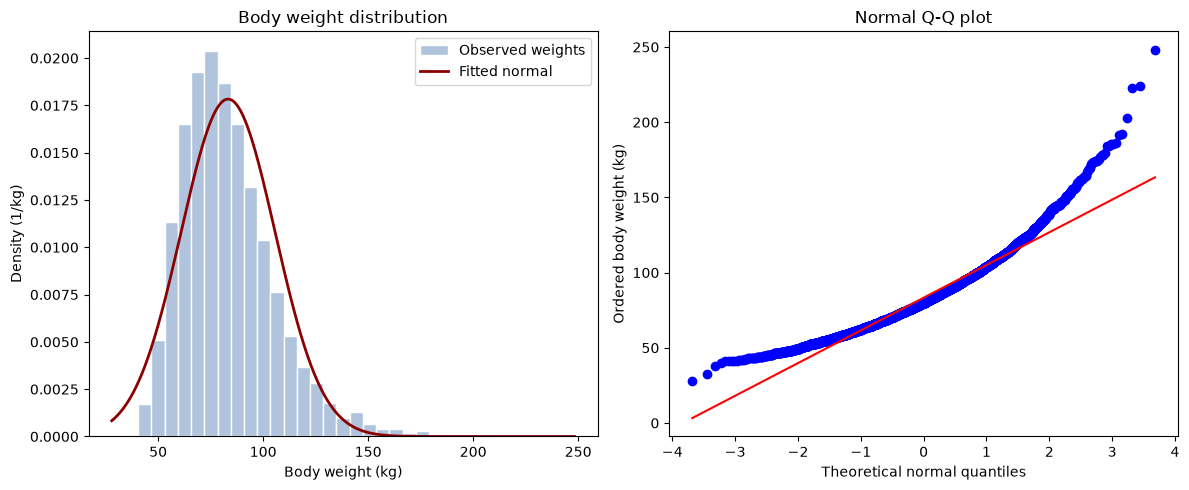

In [13]:
from scipy import stats

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ۱. هیستوگرام وزن بدن بر مقیاس چگالی
axes[0].hist(
    weights,
    bins=35,
    density=True,
    color="lightsteelblue",
    edgecolor="white",
    label="Observed weights"
)

# منحنی نرمال با میانگین و انحراف معیار داده‌ها
x_grid = np.linspace(weights.min(), weights.max(), 500)

normal_density = stats.norm.pdf(
    x_grid,
    loc=mean_weight,
    scale=std_weight
)

axes[0].plot(
    x_grid,
    normal_density,
    color="darkred",
    linewidth=2,
    label="Fitted normal"
)

axes[0].set_title("Body weight distribution")
axes[0].set_xlabel("Body weight (kg)")
axes[0].set_ylabel("Density (1/kg)")
axes[0].legend()

# ۲. مقایسهٔ چندک‌های داده با چندک‌های توزیع نرمال
stats.probplot(weights, dist="norm", plot=axes[1])

axes[1].set_title("Normal Q-Q plot")
axes[1].set_xlabel("Theoretical normal quantiles")
axes[1].set_ylabel("Ordered body weight (kg)")

fig.tight_layout()

figure_dir = ROOT / "figures" / "phase2"
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "weight_normal_diagnostics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
# چارک‌ها و فاصلهٔ بین چارکی
q1 = weights.quantile(0.25)
q3 = weights.quantile(0.75)
iqr = q3 - q1

# حدود شناسایی نقاط دورافتاده
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

below = weights < lower_bound
above = weights > upper_bound
outlier_mask = below | above

outlier_summary = pd.DataFrame({
    "Quantity": [
        "Q1 (kg)",
        "Q3 (kg)",
        "IQR (kg)",
        "Lower bound (kg)",
        "Upper bound (kg)",
        "Count below lower bound",
        "Count above upper bound",
        "Total flagged",
        "Flagged percent"
    ],
    "Value": [
        q1,
        q3,
        iqr,
        lower_bound,
        upper_bound,
        below.sum(),
        above.sum(),
        outlier_mask.sum(),
        100 * outlier_mask.mean()
    ]
})

display(outlier_summary.round(4))

,Quantity,Value
0,Q1 (kg),67.5500
1,Q3 (kg),95.4000
2,IQR (kg),27.8500
3,Lower bound (kg),25.7750
4,Upper bound (kg),137.1750
5,Count below lower bound,0.0000
6,Count above upper bound,151.0000
7,Total flagged,151.0000
8,Flagged percent,2.5238


In [15]:
# احتمال مشاهده‌شده در داده
p_observed = p_A

# احتمال وزن حداقل ۹۰ در مدل نرمال برازش‌شده
# sf یعنی احتمال قرارگرفتن بالاتر از آستانه
p_normal = stats.norm.sf(
    90,
    loc=mean_weight,
    scale=std_weight
)

normal_comparison = pd.DataFrame({
    "Method": ["Observed data", "Fitted normal"],
    "Probability": [p_observed, p_normal],
    "Percent": [100 * p_observed, 100 * p_normal]
})

display(normal_comparison.round(4))

gap_pp = 100 * (p_normal - p_observed)
print(f"Normal minus observed: {gap_pp:.2f} percentage points")

,Method,Probability,Percent
0,Observed data,0.3241,32.4085
1,Fitted normal,0.3822,38.2152


Normal minus observed: 5.81 percentage points


Empirical covariance: -25.7837 kg·year


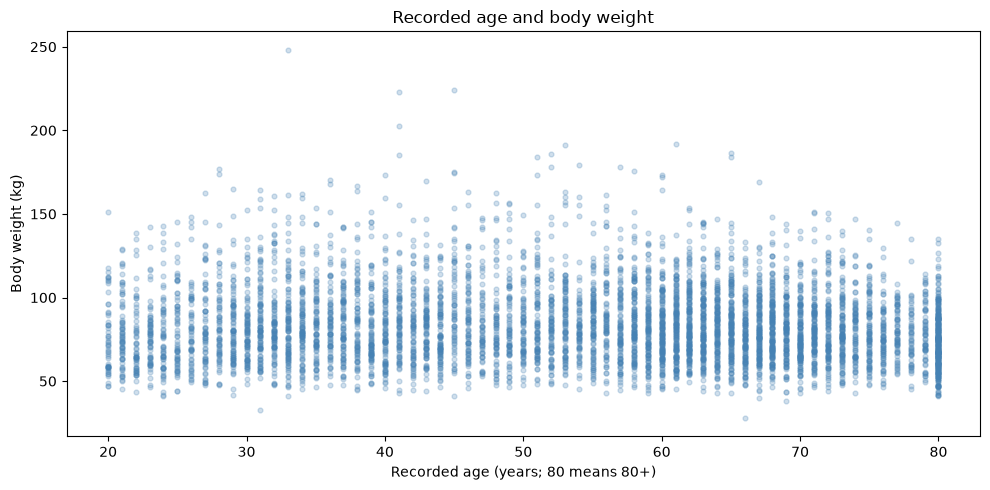

In [16]:
ages = df["Y_age"]
body_weights = df["X_weight"]

# کوواریانس توزیع تجربی با مخرج N
cov_age_weight = (
    (ages - ages.mean())
    * (body_weights - body_weights.mean())
).mean()

print(
    f"Empirical covariance: {cov_age_weight:.4f} kg·year"
)

# نمودار پراکنش
fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(
    ages,
    body_weights,
    s=12,
    alpha=0.25,
    color="steelblue"
)

ax.set_title("Recorded age and body weight")
ax.set_xlabel("Recorded age (years; 80 means 80+)")
ax.set_ylabel("Body weight (kg)")

fig.tight_layout()

figure_dir = ROOT / "figures" / "phase2"
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "age_weight_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
# وزن نمونه‌گیری معاینه
survey_weights = df["WTMEC2YR"]

# احتمال خام: سهم برابر برای هر فرد
p_unweighted = df["I_A"].mean()

# احتمال وزندار: سهم متناسب با وزن نمونه‌گیری
p_weighted = np.average(
    df["I_A"],
    weights=survey_weights
)

weighted_comparison = pd.DataFrame({
    "Method": ["Unweighted", "MEC weighted"],
    "Probability": [p_unweighted, p_weighted],
    "Percent": [
        100 * p_unweighted,
        100 * p_weighted
    ]
})

display(weighted_comparison.round(4))

difference_pp = 100 * (p_weighted - p_unweighted)

print(
    f"Weighted minus unweighted: "
    f"{difference_pp:.2f} percentage points"
)

,Method,Probability,Percent
0,Unweighted,0.3241,32.4085
1,MEC weighted,0.3332,33.3221


Weighted minus unweighted: 0.91 percentage points


In [18]:
# پوشهٔ خروجی جدول‌های فاز دوم
table_dir = ROOT / "reports" / "phase2" / "tables"
table_dir.mkdir(parents=True, exist_ok=True)

tables = {
    "marginal_joint_probabilities": probability_table,
    "conditional_probabilities": conditional_table,
    "independence_check": independence_table,
    "bayes_check": bayes_table,
    "bernoulli_summary": bernoulli_table,
    "binomial_summary": binomial_table,
    "subsample_model_comparison": comparison_table,
    "weight_summary": weight_summary,
    "outlier_summary": outlier_summary,
    "normal_probability_comparison": normal_comparison,
    "weighted_probability_comparison": weighted_comparison,

    "age_weight_covariance": pd.DataFrame({
        "Quantity": ["Empirical covariance (kg*year)"],
        "Value": [cov_age_weight]
    })
}

for name, table in tables.items():
    table.to_csv(
        table_dir / f"{name}.csv",
        index=False,
        encoding="utf-8-sig"
    )

print(f"Saved {len(tables)} tables.")
print("Folder:", table_dir)

Saved 12 tables.
Folder: c:\Users\reg\Desktop\aboutN\Amar\reports\phase2\tables


## جمع‌بندی نتایج فاز دوم

### احتمال‌های تجربی، شرطی و استقلال
در نمونهٔ نهایی، ۱۹۳۹ نفر از ۵۹۸۳ نفر وزن حداقل ۹۰ کیلوگرم دارند؛
بنابراین احتمال تجربی رویداد A برابر ۰٫۳۲۴۱ است.

احتمال وزن حداقل ۹۰ کیلوگرم در مردان ۰٫۴۱۵۹ و در زنان ۰٫۲۴۹۲ است.
اختلاف دو گروه حدود ۱۶٫۶۸ واحد درصد است. این اختلاف صرفاً توصیفی است.

احتمال مشترک A و B برابر ۰٫۱۸۶۹ است، درحالی‌که حاصل‌ضرب احتمال‌های
حاشیه‌ای برابر ۰٫۱۴۵۶ است. بنابراین دو رویداد در توزیع تجربی نمونه
مستقل نیستند. این مقایسه، آزمون رسمی استقلال در جمعیت نیست.

با استفاده از قضیهٔ بیز، احتمال مردبودن در میان افراد دارای وزن حداقل
۹۰ کیلوگرم برابر ۰٫۵۷۶۶ به دست آمد. محاسبهٔ مستقیم از فراوانی‌ها
نیز همین مقدار را تأیید کرد.

### متغیر برنولی و مدل دوجمله‌ای
شاخص رویداد A دارای میانگین ۰٫۳۲۴۱ و واریانس ۰٫۲۱۹۱ است.

برای شمارش افراد دارای رویداد A در گروه‌های ۳۰نفری، مدل دوجمله‌ای
با احتمال موفقیت ۰٫۳۲۴۱ بررسی شد. امید و واریانس این مدل به‌ترتیب
۹٫۷۲۲۵ و ۶٫۵۷۱۶ هستند.

با بذر ثابت ۱۴۰۵، تعداد ۱۰٬۰۰۰ زیرنمونهٔ ۳۰نفری انتخاب شد.
انتخاب داخل هر زیرنمونه بدون جایگذاری بود؛ بنابراین مدل دقیق
شمارش، فوق‌هندسی است. چون کسر نمونه‌گیری حدود ۰٫۵٪ است،
تقریب دوجمله‌ای به مدل دقیق نزدیک است.

میانگین و واریانس شمارش‌های شبیه‌سازی‌شده به‌ترتیب ۹٫۷۵۶۰ و
۶٫۴۷۱۱ به دست آمد. اختلاف جزئی با مقادیر نظری ناشی از نوسان
تصادفی شبیه‌سازی است. این آزمایش، طرح اصلی پیمایش NHANES
را بازسازی نمی‌کند.

### توزیع وزن بدن و تقریب نرمال
میانگین وزن بدن ۸۳٫۲۹۲۰ کیلوگرم و میانه ۷۹٫۹ کیلوگرم است.
واریانس تجربی ۵۰۰٫۵۲۶۰ کیلوگرم مربع و انحراف معیار تجربی
۲۲٫۳۷۲۴ کیلوگرم است. این مقادیر پراکندگی وزن افراد را توصیف
می‌کنند و خطای معیار برآورد میانگین نیستند.

چولگی مثبت ۱٫۱۰۸۹ و انحراف نقاط نمودار Q–Q از خط مرجع،
به‌ویژه در انتهای راست، نشان می‌دهند تقریب نرمال دقیق نیست.
مدل نرمال، احتمال وزن حداقل ۹۰ کیلوگرم را حدود ۳۸٫۲۲٪
برآورد می‌کند، درحالی‌که مقدار مشاهده‌شده ۳۲٫۴۱٪ است.

با قاعدهٔ ۱٫۵ برابر IQR، تعداد ۱۵۱ نفر، معادل ۲٫۵۲٪ نمونه،
بالاتر از حد ۱۳۷٫۱۷۵ کیلوگرم علامت‌گذاری شدند.
هیچ مشاهده‌ای صرفاً به دلیل دورافتاده‌بودن حذف نشد؛
زیرا دورافتاده‌بودن به‌تنهایی اثبات خطای اندازه‌گیری نیست.

### رابطهٔ سن و وزن
کوواریانس تجربی سن ثبت‌شده و وزن برابر ۲۵٫۷۸۳۷− کیلوگرم‌سال است.
این مقدار جهت کلی منفی رابطه را نشان می‌دهد، اما اندازهٔ آن
به واحدها وابسته است و به‌تنهایی شدت رابطه را مشخص نمی‌کند.
نمودار پراکنش نیز پراکندگی زیاد وزن در سن‌های مختلف را نشان می‌دهد.

### اثر وزن‌های نمونه‌گیری
احتمال خام وزن حداقل ۹۰ کیلوگرم برابر ۳۲٫۴۱٪ و نسخهٔ وزندار
با WTMEC2YR برابر ۳۳٫۳۲٪ است؛ یعنی حدود ۰٫۹۱ واحد درصد افزایش.

هر دو محاسبه روی افراد یکسان انجام شدند. تفاوت نشان می‌دهد
فراوانی نسبی در نمونه لزوماً با برآورد نسبت در جمعیت برابر نیست.

## محدودیت‌های تحلیل
- تحلیل به افراد دارای اطلاعات لازم محدود است؛ حذف موارد ناقص
  ممکن است موجب سوگیری شود و وزن‌دهی رفع کامل آن را تضمین نمی‌کند.
- سن ۸۰ در داده به معنی ۸۰ سال و بیشتر است؛ سن دقیق این افراد
  در دسترس نیست.
- داده‌ها مقطعی‌اند؛ رابطهٔ سن و وزن، تغییر وزن یک فرد در گذر زمان
  یا رابطهٔ علّی را اثبات نمی‌کند.
- محاسبهٔ نسبت وزندار، به‌تنهایی به معنی لحاظ‌کردن طرح پیچیدهٔ
  پیمایش در برآورد خطای معیار نیست.
- آستانهٔ وزن ۹۰ کیلوگرم صرفاً تحلیلی است و تفسیر پزشکی ندارد.

# فاز دوم پروژهٔ آمار — احتمال و توزیع‌های احتمالی

## موضوع و مسیر پروژه
مسیر الف: داده‌های NHANES 2021–2023.
موضوع پروژه، بررسی ارتباط سن و جنس ثبت‌شده با وزن بدن در بزرگسالان است.

## جمعیت تحلیلی و آماده‌سازی داده
هر مشاهده نمایندهٔ یک شرکت‌کننده با شناسهٔ SEQN است.
پس از بررسی یکتایی شناسه‌ها، فایل‌های DEMO_L و BMX_L با اتصال داخلی
بر اساس SEQN ادغام شدند. مطابق کد فاز اول، افراد ۲۰ سال و بیشتر
به‌عنوان بزرگسال انتخاب شدند.

پس از اتصال، ۶۰۶۴ بزرگسال وجود داشت. وزن بدن ۸۱ نفر گمشده بود.
با کنارگذاشتن موارد ناقص و محدودکردن جنس ثبت‌شده به کدهای ۱ و ۲
و وزن نمونه‌گیری معاینه به مقادیر مثبت، نمونهٔ نهایی شامل ۵۹۸۳ نفر شد.
مقادیر گمشده با صفر جایگزین نشدند.

## متغیرها و رویدادها
- X: وزن بدن بر حسب کیلوگرم، از متغیر BMXWT.
- Y: سن ثبت‌شده بر حسب سال، از متغیر RIDAGEYR.
- A: وزن بدن حداقل ۹۰ کیلوگرم باشد.
- B: جنس ثبت‌شده مرد باشد؛ یعنی RIAGENDR برابر ۱ باشد.
- I_A: شاخص رویداد A؛ در صورت وقوع برابر ۱ و در غیر این صورت برابر ۰.

آستانهٔ ۹۰ کیلوگرم یک انتخاب تحلیلی برای تبدیل وزن به رویداد دودویی است
و تعریف چاقی یا آستانهٔ تشخیص پزشکی نیست.

## چارچوب تحلیل
در محاسبات بدون وزن، انتخاب یک فرد به‌صورت یکنواخت از نمونهٔ نهایی
مبنای احتمال تجربی است. در بخش وزندار از WTMEC2YR، وزن نمونه‌گیری
معاینه، استفاده می‌شود؛ این متغیر با وزن بدن متفاوت است.

تحلیل‌های این فاز توصیفی‌اند و شامل آزمون فرض، فاصلهٔ اطمینان
یا نتیجه‌گیری علّی نیستند.